# Exercício 4 — Outliers
**Disciplina:** Ciência de Dados · **Etapa CRISP-DM:** Preparação dos Dados
**Dataset:** Diamonds (seaborn) — `sns.load_dataset('diamonds')`

**Objetivo:** distinguir **erros de registro** de **valores extremos legítimos** e comparar três estratégias de tratamento.

**Dicionário das colunas:** `carat` = peso em quilates · `depth` = profundidade total em % (`2·z / (x+y) · 100`) · `table` = largura do topo em % · `price` = preço em US$ · `x` = comprimento (mm) · `y` = largura (mm) · `z` = profundidade (mm).

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

In [2]:
# CARREGAMENTO DOS DADOS
df = sns.load_dataset('diamonds')
print('Dimensões:', df.shape, '| ausentes:', df.isna().sum().sum(), '| duplicadas exatas:', df.duplicated().sum())
df.head()

Dimensões: (53940, 10) | ausentes: 0 | duplicadas exatas: 146


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.230,Ideal,E,SI2,61.500,55.000,326,3.950,3.980,2.430
1,0.210,Premium,E,SI1,59.800,61.000,326,3.890,3.840,2.310
2,0.230,Good,E,VS1,56.900,65.000,327,4.050,4.070,2.310
3,0.290,Premium,I,VS2,62.400,58.000,334,4.200,4.230,2.630
4,0.310,Good,J,SI2,63.300,58.000,335,4.340,4.350,2.750


## Estatísticas descritivas e valores impossíveis

In [3]:
# ESTATÍSTICAS DESCRITIVAS E VALORES IMPOSSÍVEIS
num_cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
carat,"53,940.000",0.798,0.474,0.200,0.400,0.700,1.040,5.010
depth,"53,940.000",61.749,1.433,43.000,61.000,61.800,62.500,79.000
table,"53,940.000",57.457,2.234,43.000,56.000,57.000,59.000,95.000
price,"53,940.000","3,932.800","3,989.440",326.000,950.000,"2,401.000","5,324.250","18,823.000"
x,"53,940.000",5.731,1.122,0.000,4.710,5.700,6.540,10.740
y,"53,940.000",5.735,1.142,0.000,4.720,5.710,6.540,58.900
z,"53,940.000",3.539,0.706,0.000,2.910,3.530,4.040,31.800


In [4]:
# Valores fisicamente impossíveis: dimensões <= 0 mm
zeros = df[(df[['x', 'y', 'z']] <= 0).any(axis=1)]
print('Linhas com alguma dimensão igual a 0:', len(zeros))
print('Dessas, com x, y e z = 0 ao mesmo tempo:', (zeros[['x', 'y', 'z']] == 0).all(axis=1).sum())
display(zeros.head(8))

# Valores extremos nas dimensões
print('\nMaiores valores de y:'); display(df.nlargest(3, 'y')[['carat', 'depth', 'price', 'x', 'y', 'z']])
print('Maiores valores de z:'); display(df.nlargest(3, 'z')[['carat', 'depth', 'price', 'x', 'y', 'z']])

Linhas com alguma dimensão igual a 0: 20
Dessas, com x, y e z = 0 ao mesmo tempo: 7


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.000,Premium,G,SI2,59.100,59.000,3142,6.550,6.480,0.000
2314,1.010,Premium,H,I1,58.100,59.000,3167,6.660,6.600,0.000
4791,1.100,Premium,G,SI2,63.000,59.000,3696,6.500,6.470,0.000
5471,1.010,Premium,F,SI2,59.200,58.000,3837,6.500,6.470,0.000
10167,1.500,Good,G,I1,64.000,61.000,4731,7.150,7.040,0.000
11182,1.070,Ideal,F,SI2,61.600,56.000,4954,0.000,6.620,0.000
11963,1.000,Very Good,H,VS2,63.300,53.000,5139,0.000,0.000,0.000
13601,1.150,Ideal,G,VS2,59.200,56.000,5564,6.880,6.830,0.000



Maiores valores de y:


,carat,depth,price,x,y,z
24067,2.000,58.900,12210,8.090,58.900,8.060
49189,0.510,61.800,2075,5.150,31.800,5.120
27415,5.010,65.500,18018,10.740,10.540,6.980


Maiores valores de z:


,carat,depth,price,x,y,z
48410,0.510,61.800,1970,5.120,5.150,31.800
24067,2.000,58.900,12210,8.090,58.900,8.060
27415,5.010,65.500,18018,10.740,10.540,6.980


**O que as estatísticas revelam:**
- **Dimensão igual a zero:** 20 diamantes têm `x`, `y` ou `z` = 0. Um diamante não pode ter 0 mm de comprimento, largura ou altura, e isso é **impossível**. Provavelmente é um valor que faltou e foi preenchido com 0 (um ausente "disfarçado", como no Exercício 3).
- **`y` = 58,9 mm e `z` = 31,8 mm:** um diamante de 2 quilates mede cerca de 8 mm. Um de 58,9 mm seria do tamanho de uma bola de golfe. O `max` de `y` (58,9) está a quilômetros dos outros (os demais chegam a ~10,5), e o de `z` (31,8) idem.
- Todos esses valores impossíveis estão "escondidos" em colunas cujo resto é bem-comportado: sem olhar `min` e `max`, passariam despercebidos.

## Detecção — Z-score
O Z-score marca como outlier todo valor a mais de **3 desvios-padrão** da média: `|z| = |(x − média) / desvio| > 3`.

In [5]:
# DETECÇÃO — Z-SCORE
LIMITE_Z = 3
mask_z = pd.DataFrame({c: np.abs(stats.zscore(df[c])) > LIMITE_Z for c in num_cols})
z_cont = mask_z.sum().rename('outliers_zscore')
z_cont.to_frame().T

,carat,depth,table,price,x,y,z
outliers_zscore,439,685,336,1206,43,34,55


## Detecção — IQR
O IQR marca como outlier o que está fora de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`.

In [6]:
# DETECÇÃO — IQR
def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lims = {c: limites_iqr(df[c]) for c in num_cols}
mask_iqr = pd.DataFrame({c: (df[c] < lims[c][0]) | (df[c] > lims[c][1]) for c in num_cols})

comparacao = pd.DataFrame({
    'limite_inferior_IQR': {c: lims[c][0] for c in num_cols},
    'limite_superior_IQR': {c: lims[c][1] for c in num_cols},
    'outliers_zscore': mask_z.sum(),
    'outliers_IQR': mask_iqr.sum(),
    'ambos': (mask_z & mask_iqr).sum(),
    'só_IQR': (~mask_z & mask_iqr).sum(),
    'só_zscore': (mask_z & ~mask_iqr).sum(),
})
comparacao['pct_IQR'] = comparacao['outliers_IQR'] / len(df) * 100
display(comparacao)

print('Linhas com outlier em ALGUMA coluna — Z-score:', mask_z.any(axis=1).sum(), '| IQR:', mask_iqr.any(axis=1).sum())

,limite_inferior_IQR,limite_superior_IQR,outliers_zscore,outliers_IQR,ambos,só_IQR,só_zscore,pct_IQR
carat,-0.560,2.000,439,1889,439,1450,0,3.502
depth,58.750,64.750,685,2545,685,1860,0,4.718
table,51.500,63.500,336,605,336,269,0,1.122
price,"-5,611.375","11,885.625",1206,3540,1206,2334,0,6.563
x,1.965,9.285,43,32,32,0,11,0.059
y,1.990,9.270,34,29,29,0,5,0.054
z,1.215,5.735,55,49,49,0,6,0.091


Linhas com outlier em ALGUMA coluna — Z-score: 2350 | IQR: 6416


**Comparação:**
- Em `carat`, `depth`, `table` e `price` o **IQR aponta muito mais registros** do que o Z-score (por exemplo, `price`: 3.540 contra 1.206; `depth`: 2.545 contra 685). Todo ponto marcado pelo Z-score também é marcado pelo IQR (coluna `só_zscore` = 0). O motivo é a forma das distribuições (ver reflexão 1): em dados assimétricos à direita ou com caudas pesadas, a média e o desvio-padrão são puxados pelos próprios extremos, o que "infla" a régua do Z-score. Em `price`, o limite do Z-score é ≈ 15.900, contra ≈ 11.900 do IQR. O IQR, baseado em quartis, não é puxado.
- Em `x`, `y` e `z` (aproximadamente simétricas, com poucos valores muito fora) os métodos ficam **próximos** (30 a 55 pontos), e o Z-score até aponta um pouco mais.
- No total, 2.350 linhas têm algum outlier pelo Z-score e 6.416 pelo IQR. Os métodos **não concordam** e nenhum dos dois diz se o ponto é *erro* ou *raro*; isso exige critério (próximas seções).
- *Nota:* o dataset também tem 146 linhas exatamente duplicadas. Em uma base de itens individuais isso pode ser legítimo (dois diamantes com as mesmas características), por isso não foram tratadas aqui; o foco do exercício é outlier.

## Visualizações

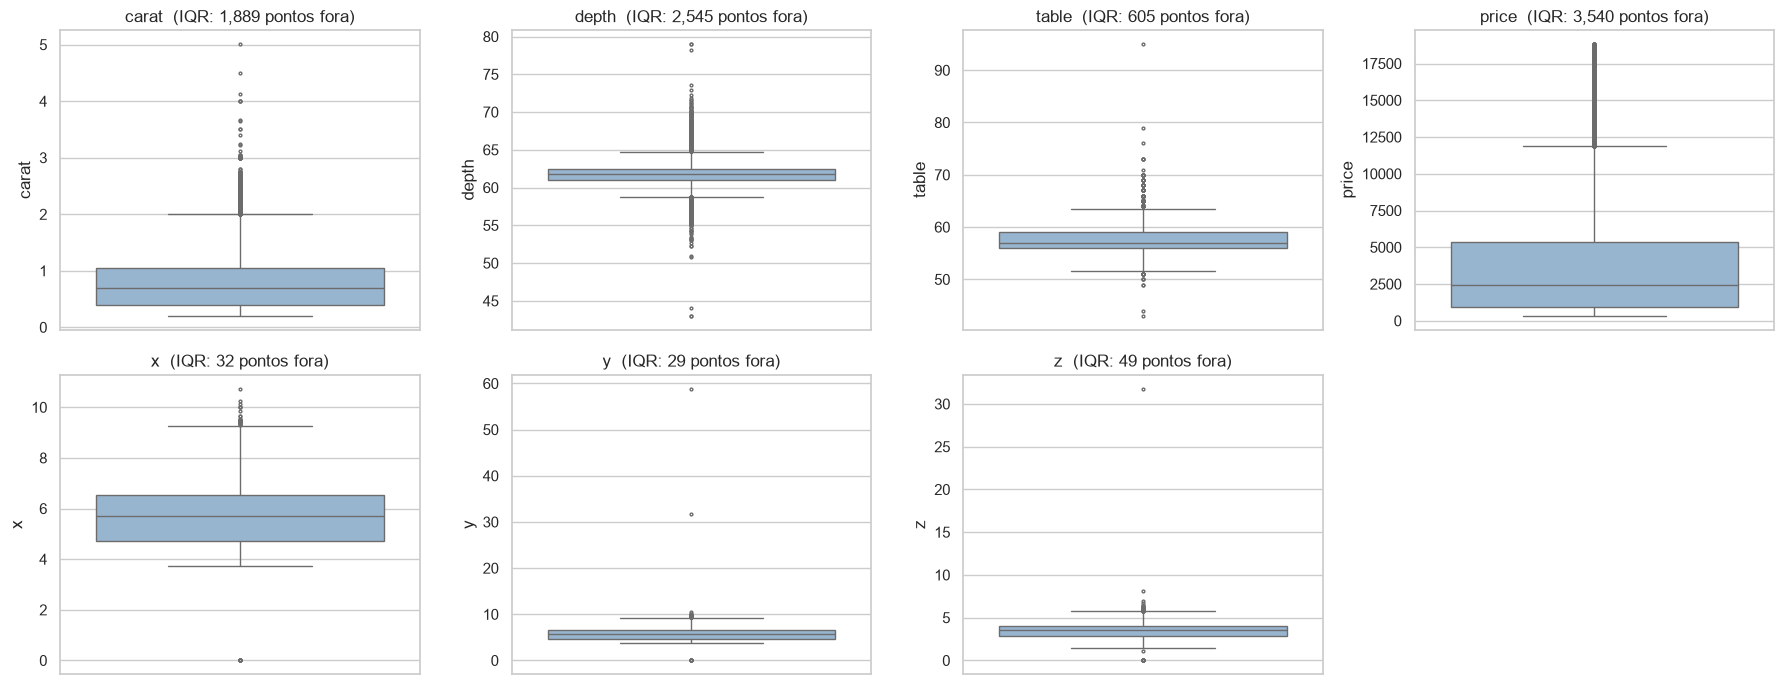

In [7]:
# VISUALIZAÇÕES — boxplots por coluna
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color='#8FB5D9', fliersize=2)
    ax.set_title(f'{c}  (IQR: {mask_iqr[c].sum():,} pontos fora)')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

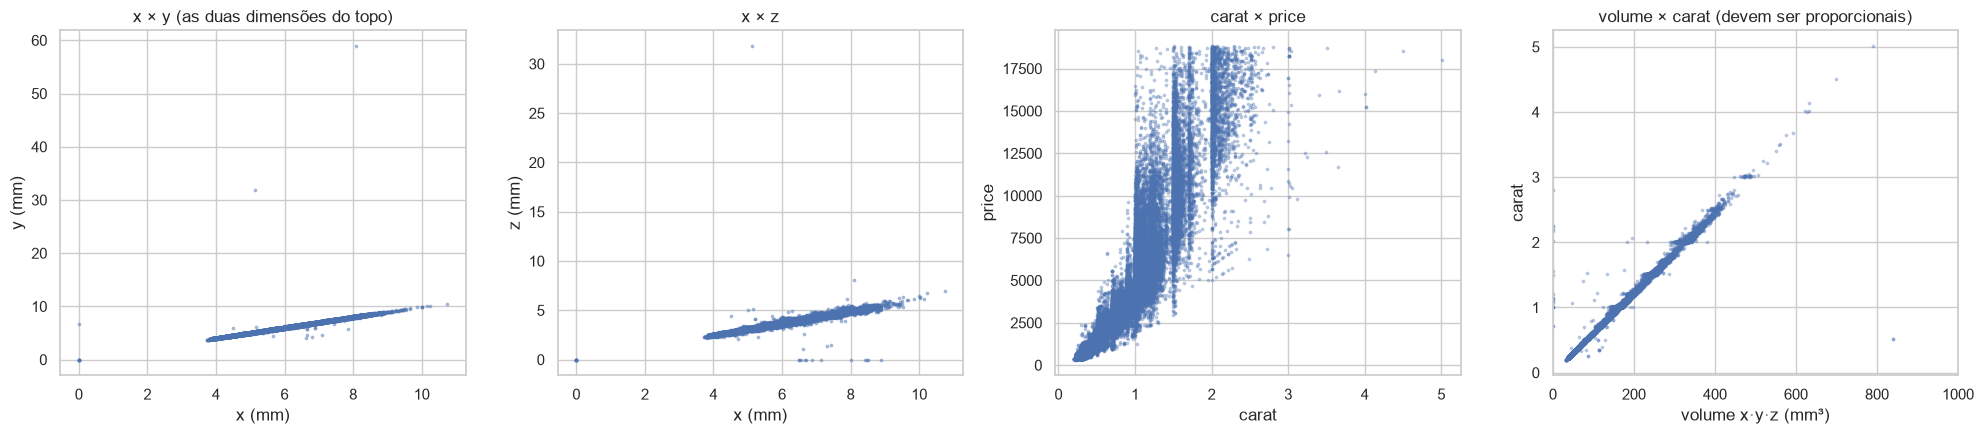

In [8]:
# VISUALIZAÇÕES — dispersão entre pares que fazem sentido juntos
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].scatter(df['x'], df['y'], s=3, alpha=0.4); axes[0].set_xlabel('x (mm)'); axes[0].set_ylabel('y (mm)'); axes[0].set_title('x × y (as duas dimensões do topo)')
axes[1].scatter(df['x'], df['z'], s=3, alpha=0.4); axes[1].set_xlabel('x (mm)'); axes[1].set_ylabel('z (mm)'); axes[1].set_title('x × z')
axes[2].scatter(df['carat'], df['price'], s=3, alpha=0.3); axes[2].set_xlabel('carat'); axes[2].set_ylabel('price'); axes[2].set_title('carat × price')
vol = df['x'] * df['y'] * df['z']
axes[3].scatter(vol, df['carat'], s=3, alpha=0.3); axes[3].set_xlabel('volume x·y·z (mm³)'); axes[3].set_ylabel('carat'); axes[3].set_title('volume × carat (devem ser proporcionais)')
axes[3].set_xlim(0, 1000)
plt.tight_layout(); plt.show()

**O que os gráficos mostram:**
- Em `x × y` e `x × z`, quase todos os pontos formam uma **linha diagonal estreita** (um diamante é aproximadamente proporcional), e uns poucos pontos ficam **muito fora** da linha (`y` = 58,9; `z` = 31,8) mais os pontos em 0 no eixo. Esses são **erros**: não existe um diamante nessa proporção.
- Em `carat × price`, os pontos mais altos à direita (diamantes grandes e caros) continuam a **tendência** dos demais: preço cresce com o peso. Isso é típico de **extremo legítimo**.
- Em `volume × carat` a relação é quase linear, o que dá um jeito de checar a coerência de cada linha.

## Erro x valor extremo legítimo
**Critério.** Para decidir se um valor extremo é erro ou raro, uso a pergunta: **ele é fisicamente coerente com o resto da linha?** Um outlier **legítimo** é grande/caro, mas as demais colunas "concordam" (um diamante grande tem dimensões grandes, preço alto, etc.). Um **erro** é incoerente por si só.
1. **Dimensão ≤ 0:** erro certo (impossível).
2. **Incoerência entre `depth` e as dimensões:** `depth` deve ser igual a `2·z/(x+y)·100`. Diferença maior que **5 pontos percentuais** indica que alguma das medidas está errada (ex.: `z` digitado com a vírgula no lugar errado, `z` repetindo o quilate, ou `depth` com valor impossível). Escolhi 5 p.p. porque a diferença típica é < 0,2 p.p. (99% dos casos), então 5 p.p. é muito acima do ruído de medição.
3. **Todo o resto** que é extremo estatisticamente, mas coerente (diamantes pesados, preços altos), é tratado como **valor legítimo**.

In [9]:
# ERRO x VALOR EXTREMO LEGÍTIMO
df = df.copy()
df['depth_calc'] = 2 * df['z'] / (df['x'] + df['y']) * 100
df['dif_depth'] = (df['depth_calc'] - df['depth']).abs()

regra_zero = (df[['x', 'y', 'z']] <= 0).any(axis=1)
regra_depth = (df['dif_depth'] > 5) & ~regra_zero
df['erro_registro'] = regra_zero | regra_depth

# extremos legítimos: outlier por IQR em carat ou price, mas sem ser erro
df['extremo_legitimo'] = (mask_iqr['carat'] | mask_iqr['price']) & ~df['erro_registro']

print(pd.Series({
    'Erros — dimensão ≤ 0': regra_zero.sum(),
    'Erros — depth incoerente com x,y,z': regra_depth.sum(),
    'TOTAL de erros de registro': df['erro_registro'].sum(),
    'Extremos legítimos (carat/price fora do IQR)': df['extremo_legitimo'].sum(),
}, name='linhas').to_frame())

print('\nExemplos de erros de registro (por incoerência de depth):')
display(df[regra_depth].sort_values('dif_depth', ascending=False)[['carat', 'depth', 'depth_calc', 'price', 'x', 'y', 'z']].head(8))

print('Caso do z = 31,8: depth informado = 61,8; com z = 3,18 o depth calculado seria',
      round(2 * 3.18 / (5.12 + 5.15) * 100, 1), '-> provável erro de vírgula')

                                              linhas
Erros — dimensão ≤ 0                              20
Erros — depth incoerente com x,y,z                27
TOTAL de erros de registro                        47
Extremos legítimos (carat/price fora do IQR)    3743

Exemplos de erros de registro (por incoerência de depth):


,carat,depth,depth_calc,price,x,y,z
48410,0.510,61.800,619.279,1970,5.120,5.150,31.800
14635,1.070,60.600,16.102,5909,6.620,6.670,1.070
20694,1.530,61.900,20.496,8971,7.430,7.500,1.530
21654,1.410,60.700,19.408,9752,7.310,7.220,1.410
49905,0.500,63.700,100.697,2180,5.010,5.040,5.060
24067,2.000,58.900,24.063,12210,8.090,58.900,8.060
49189,0.510,61.800,27.713,2075,5.150,31.800,5.120
34282,0.390,61.200,84.330,468,4.510,6.020,4.440


Caso do z = 31,8: depth informado = 61,8; com z = 3,18 o depth calculado seria 61.9 -> provável erro de vírgula


Extremos legítimos — diferença mediana entre depth e depth calculado: 0.027 p.p. (mesma ordem de grandeza do restante)

Diamantes com mais de 4 quilates (todos coerentes e todos considerados legítimos):


,carat,cut,color,clarity,depth,depth_calc,price,x,y,z,erro_registro
25998,4.010,Premium,I,I1,61.000,60.968,15223,10.140,10.100,6.170,False
25999,4.010,Premium,J,I1,62.500,62.525,15223,10.020,9.940,6.240,False
27130,4.130,Fair,H,I1,64.800,64.786,17329,10.000,9.850,6.430,False
27415,5.010,Fair,J,I1,65.500,65.602,18018,10.740,10.540,6.980,False
27630,4.500,Fair,J,I1,65.800,65.915,18531,10.230,10.160,6.720,False


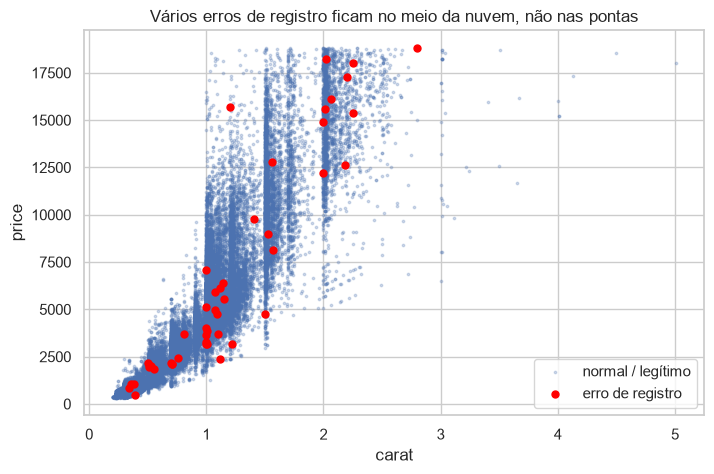

In [10]:
# Extremos legítimos: confirmo que são fisicamente coerentes
leg = df[df['extremo_legitimo']]
print('Extremos legítimos — diferença mediana entre depth e depth calculado:', round(leg['dif_depth'].median(), 3), 'p.p. (mesma ordem de grandeza do restante)')
print('\nDiamantes com mais de 4 quilates (todos coerentes e todos considerados legítimos):')
display(df[df['carat'] > 4][['carat', 'cut', 'color', 'clarity', 'depth', 'depth_calc', 'price', 'x', 'y', 'z', 'erro_registro']])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df.loc[~df['erro_registro'], 'carat'], df.loc[~df['erro_registro'], 'price'], s=3, alpha=0.25, label='normal / legítimo')
ax.scatter(df.loc[df['erro_registro'], 'carat'], df.loc[df['erro_registro'], 'price'], s=25, color='red', label='erro de registro')
ax.set_xlabel('carat'); ax.set_ylabel('price'); ax.legend(); ax.set_title('Vários erros de registro ficam no meio da nuvem, não nas pontas')
plt.show()

**Conclusão da classificação:**
- Os **erros de registro** (dimensão zero, valores como 58,9 e 31,8, `z` copiado do quilate, `depth` com valores como 43) **não estão (todos) nas pontas** de `price` ou `carat`: o gráfico mostra que vários, como os diamantes de ≈ 1 quilate com dimensão 0, estão no meio da nuvem de dados. Um filtro puramente estatístico em `price` **não os pegaria** e ainda removeria diamantes legítimos. Só a regra de coerência física os encontra.
- Os **extremos legítimos** (diamantes grandes e caros) obedecem à lógica física e à relação preço×peso. São exatamente a parte "rara, porém real" que o enunciado descreve.

## Tratamento — remoção / capping / transformação
**Passo 0 (comum a todas as estratégias):** os erros de registro são **sempre removidos**, porque não são "dados raros", são dados errados. As três estratégias abaixo tratam, então, os **extremos de `price`** (a coluna alvo da análise) sobre a base já sem erros.

In [11]:
# TRATAMENTO — REMOÇÃO / CAPPING / TRANSFORMAÇÃO
base = df[~df['erro_registro']].drop(columns=['depth_calc', 'dif_depth', 'erro_registro', 'extremo_legitimo']).copy()
print(f'Base original: {len(df):,} | após remover erros de registro: {len(base):,} (-{len(df) - len(base)})')

inf, sup = limites_iqr(base['price'])
print(f'Limites IQR de price: [{inf:,.0f}, {sup:,.0f}]')

# 1) Remoção
df_remocao = base[(base['price'] >= inf) & (base['price'] <= sup)].copy()

# 2) Capping (winsorização nos limites IQR)
df_capping = base.copy()
df_capping['price'] = df_capping['price'].clip(lower=max(inf, base['price'].min()), upper=sup)

# 3) Transformação (log e raiz quadrada)
df_transf = base.copy()
df_transf['price_log'] = np.log1p(df_transf['price'])
df_transf['price_sqrt'] = np.sqrt(df_transf['price'])

print(f'Linhas — remoção: {len(df_remocao):,} (perde {len(base) - len(df_remocao):,}) | capping: {len(df_capping):,} | transformação: {len(df_transf):,}')

Base original: 53,940 | após remover erros de registro: 53,893 (-47)
Limites IQR de price: [-5,610, 11,882]
Linhas — remoção: 50,363 (perde 3,530) | capping: 53,893 | transformação: 53,893


## Comparação entre as estratégias

In [12]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
def resumo(s):
    return pd.Series({'n': len(s), 'média': s.mean(), 'mediana': s.median(), 'desvio': s.std(), 'mín': s.min(), 'máx': s.max(),
                      'assimetria (skew)': s.skew(), 'curtose': s.kurt()})

cmp = pd.DataFrame({
    'original (com erros)': resumo(df['price']),
    'sem erros': resumo(base['price']),
    'remoção (IQR)': resumo(df_remocao['price']),
    'capping (IQR)': resumo(df_capping['price']),
    'log1p(price)': resumo(df_transf['price_log']),
    'sqrt(price)': resumo(df_transf['price_sqrt']),
})
display(cmp)

# O que se perde ao remover? Diamantes grandes desaparecem
grandes = base['carat'] >= 2
print(f"\nDiamantes de 2+ quilates: {grandes.sum():,} na base sem erros -> {(df_remocao['carat'] >= 2).sum():,} após a remoção "
      f"({(1 - (df_remocao['carat'] >= 2).sum() / grandes.sum()) * 100:.0f}% deles foram apagados)")

,original (com erros),sem erros,remoção (IQR),capping (IQR),log1p(price),sqrt(price)
n,"53,940.000","53,893.000","50,363.000","53,893.000","53,893.000","53,893.000"
média,"3,932.800","3,930.265","3,158.652","3,730.000",7.787,55.771
mediana,"2,401.000","2,401.000","2,154.000","2,401.000",7.784,49.000
desvio,"3,989.440","3,986.809","2,764.464","3,434.983",1.014,28.634
mín,326.000,326.000,326.000,326.000,5.790,18.055
máx,"18,823.000","18,823.000","11,880.000","11,881.500",9.843,137.197
assimetria (skew),1.618,1.619,1.189,1.148,0.116,0.844
curtose,2.178,2.180,0.627,0.215,-1.097,-0.110



Diamantes de 2+ quilates: 2,144 na base sem erros -> 277 após a remoção (87% deles foram apagados)


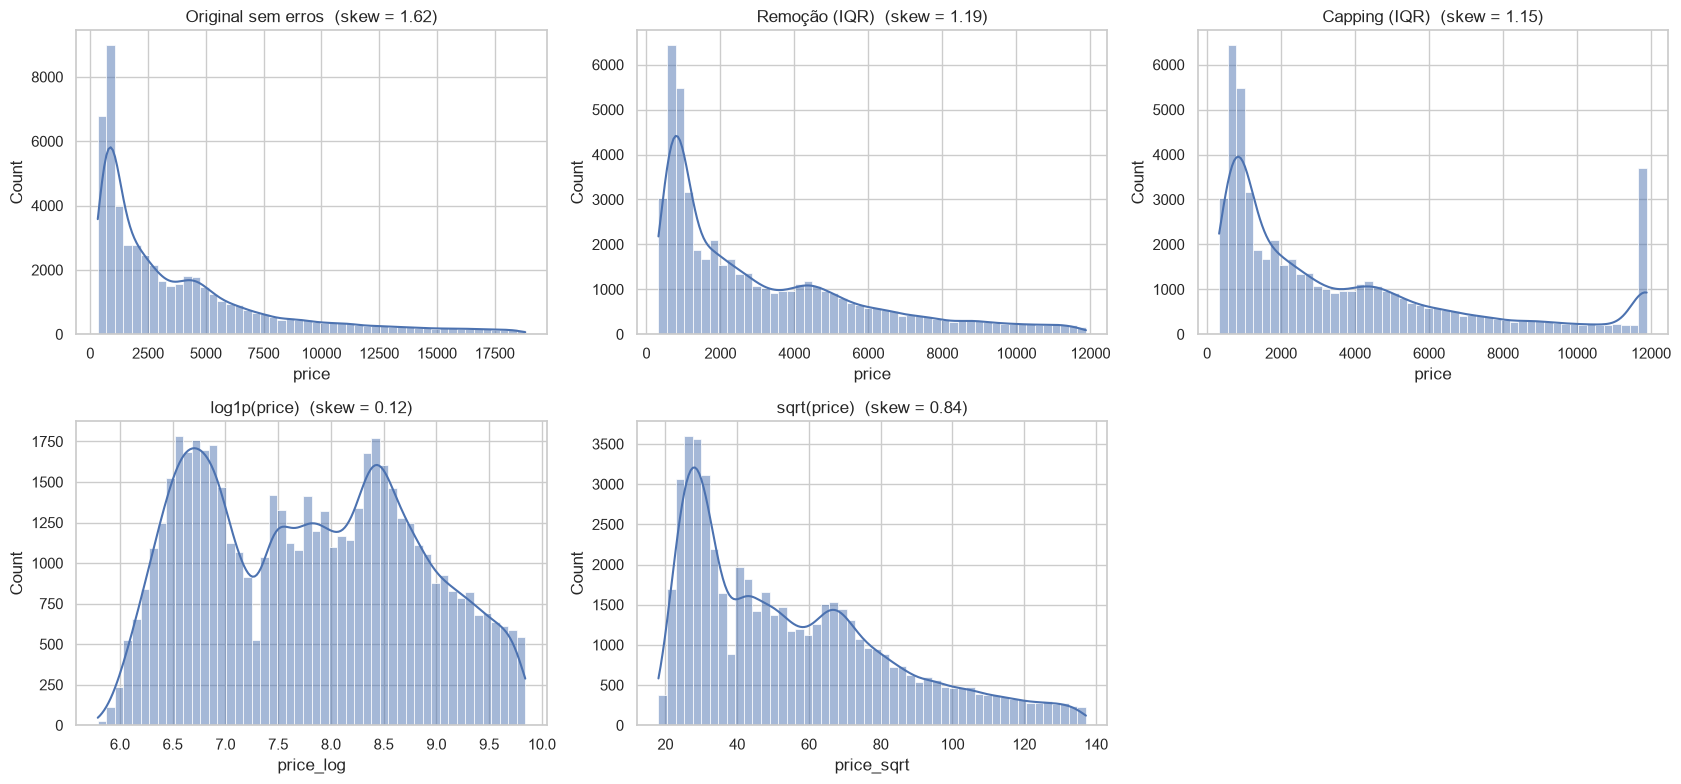

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
series = [('Original sem erros', base['price']), ('Remoção (IQR)', df_remocao['price']), ('Capping (IQR)', df_capping['price']),
          ('log1p(price)', df_transf['price_log']), ('sqrt(price)', df_transf['price_sqrt'])]
for ax, (nome, s) in zip(axes.ravel(), series):
    sns.histplot(s, bins=50, kde=True, ax=ax, color='#4C72B0')
    ax.set_title(f'{nome}  (skew = {s.skew():.2f})')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

**Impacto de cada estratégia sobre `price`:**
- **Remoção:** a média cai de 3.930 para 3.159 e o desvio de 3.987 para 2.764, mas **apaga 3.530 linhas (6,5% da base)**, e é justamente a parte mais valiosa: **87% dos diamantes de 2 quilates ou mais desaparecem** (2.144 → 277). Qualquer estudo sobre "quanto vale um diamante grande" ficaria enviesado. A assimetria continua em 1,19, porque ao apagar a cauda o IQR é recalculado e novos "outliers" apareceriam.
- **Capping:** mantém todas as 53.893 linhas e limita o efeito dos extremos (o máximo vira ≈ 11.882). A média cai menos (3.730) e a assimetria só vai de 1,62 para 1,15, mas aparece um **pico artificial** no limite superior, e o preço dos diamantes mais caros deixa de ser verdadeiro.
- **Transformação (log/raiz):** mantém **todas as linhas e todos os valores** (sem apagar nem mexer em nenhum dado) e apenas muda a escala. O log é o que mais aproxima a distribuição de uma forma simétrica (assimetria 1,62 → **0,12**); a raiz quadrada reduz menos (0,84). Para modelos que supõem simetria, é a estratégia que **menos destrói informação**.

## Respostas às perguntas de reflexão

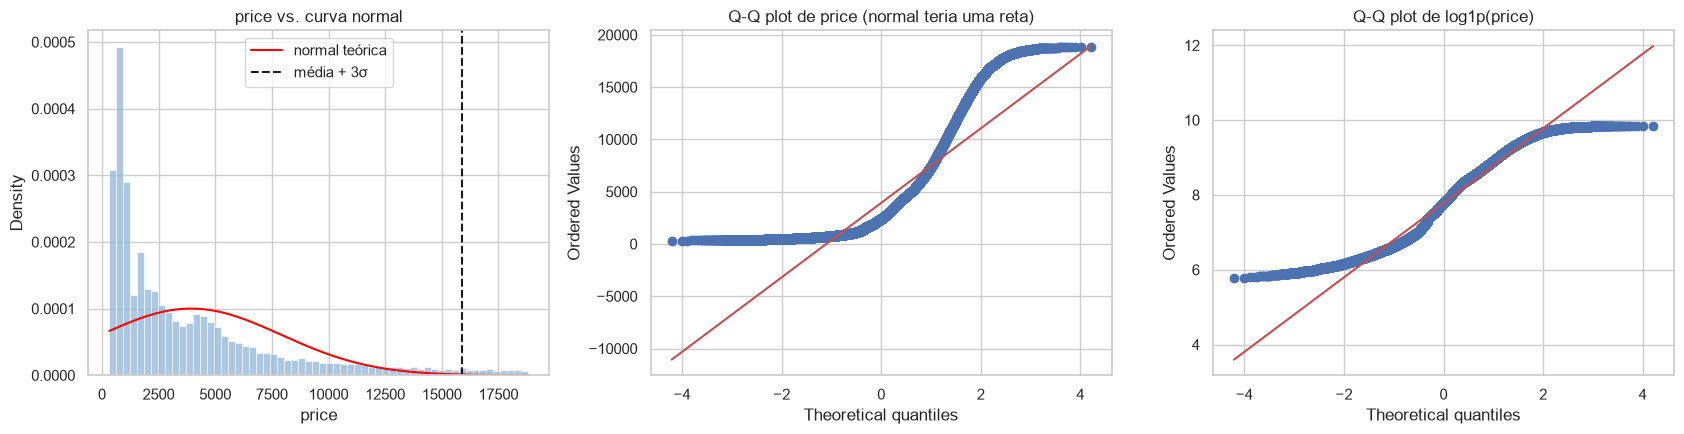

Assimetria de price: 1.62 | de log1p(price): 0.12
Fração com |z| > 3: real = 2.24%  | esperado numa normal = 0.27%
Limite do Z-score (média + 3σ) = 15,891  vs  limite do IQR = 11,882


In [14]:
# EVIDÊNCIA PARA A PERGUNTA 1 — a suposição de normalidade vale para price?
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(base['price'], bins=60, stat='density', ax=axes[0], color='#8FB5D9')
xs = np.linspace(base['price'].min(), base['price'].max(), 300)
axes[0].plot(xs, stats.norm.pdf(xs, base['price'].mean(), base['price'].std()), color='red', label='normal teórica')
axes[0].axvline(base['price'].mean() + 3 * base['price'].std(), color='k', ls='--', label='média + 3σ'); axes[0].legend()
axes[0].set_title('price vs. curva normal')
stats.probplot(base['price'], dist='norm', plot=axes[1]); axes[1].set_title('Q-Q plot de price (normal teria uma reta)')
stats.probplot(df_transf['price_log'], dist='norm', plot=axes[2]); axes[2].set_title('Q-Q plot de log1p(price)')
plt.tight_layout(); plt.show()

z_price = np.abs(stats.zscore(base['price']))
print(f"Assimetria de price: {base['price'].skew():.2f} | de log1p(price): {df_transf['price_log'].skew():.2f}")
print(f"Fração com |z| > 3: real = {(z_price > 3).mean()*100:.2f}%  | esperado numa normal = {2 * (1 - stats.norm.cdf(3)) * 100:.2f}%")
print(f"Limite do Z-score (média + 3σ) = {base['price'].mean() + 3 * base['price'].std():,.0f}  vs  limite do IQR = {sup:,.0f}")

**1. O Z-score parte de uma suposição sobre a forma da distribuição. Qual? Ela vale para `price`?**
O Z-score supõe que os dados seguem aproximadamente uma **distribuição normal** (em sino, simétrica). Só nessa forma é que "3 desvios-padrão" corresponde a algo raro (cerca de 0,27% dos valores). **Para `price` não vale**: o histograma mostra uma distribuição fortemente **assimétrica à direita** (muitos diamantes baratos e uma cauda longa de caros), e o Q-Q plot se afasta muito da reta, principalmente nas pontas. Como consequência, a fração de pontos com |z| > 3 é bem **maior** que a esperada numa normal (2,24%, contra 0,27%), o que significa que o critério "3σ" **deixa de ter o significado estatístico original**: o Z-score marca como "anormais" os diamantes caros que, em um mercado com cauda longa, são perfeitamente normais, e a média e o desvio já estão distorcidos pela própria cauda. Depois do `log1p`, o Q-Q plot fica muito mais próximo de uma reta, indicando que o log "normaliza" a distribuição.

**2. Um diamante de mais de 4 quilates é um outlier a ser removido ou um diamante raro? Como o objetivo muda a resposta?**
É **raro, não errado**: há apenas 5 diamantes acima de 4 quilates, todos com dimensões coerentes com o peso (~10 mm), `depth` consistente e preço proporcional. O que fazer depende do objetivo:
- **Precificar a loja inteira / prever preço do estoque típico:** manter pode distorcer um modelo linear, e pode-se usar uma transformação (log) ou um modelo robusto, em vez de apagar.
- **Estudar o mercado de luxo / precificar diamantes grandes:** removê-los **apagaria exatamente o objeto de estudo**.
- **Detectar fraude ou erro de cadastro:** aí o interessante é investigar cada caso individualmente.
Ou seja, "outlier" é uma propriedade estatística, e "erro" depende do contexto e do objetivo da análise.

**3. Dê um exemplo de situação em que remover outliers esconderia exatamente aquilo que o negócio quer descobrir.**
- **Detecção de fraude em cartão de crédito:** as transações fraudulentas *são* os outliers (valor ou local fora do padrão). Remover os extremos antes de analisar eliminaria exatamente o que se quer encontrar.
- **Manutenção preditiva:** a vibração ou temperatura anormal em uma máquina é o sinal de falha iminente.
- **Clientes de alto valor (varejo, banco, SaaS):** os poucos clientes que respondem por grande parte da receita aparecem como outliers de gasto. Removê-los faz a análise concluir que "o cliente típico gasta pouco" e esconde onde está o dinheiro.
- Neste mesmo dataset: se o negócio é uma joalheria que quer entender o mercado de **pedras grandes**, remover o IQR de `price` apaga a maior parte dos diamantes de 2+ quilates, como medido acima.